# < Data Science Project>

Describe goal of project, required steps, outcome and learnings

# Imports

In [281]:
# ==========================================================
# SPECIFIC MACHINE LEARNING IMPORT TEMPLATE
# ==========================================================
# --- Core Data Science & Visualization ---
import numpy as np                   # Numerical operations and arrays
import pandas as pd                  # Data manipulation and DataFrames
import matplotlib.pyplot as plt      # Core plotting library
import seaborn as sns                # Statistical visualization
# import statsmodels.api as sm         # Detailed statistical models/tests
from scipy import stats              # Advanced scientific/stats functions
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)


# --- Preprocessing & Feature Engineering ---
from sklearn.preprocessing import StandardScaler      # Standardize features (mean=0, variance=1)
# from sklearn.preprocessing import MinMaxScaler        # Scale features to a range (0 to 1)
# from sklearn.preprocessing import PolynomialFeatures  # Create non-linear feature combinations
from sklearn.decomposition import PCA                # Dimensionality reduction

# --- Model Selection & Validation ---
# from sklearn.model_selection import train_test_split  # Split data into training and testing sets
# from sklearn.model_selection import cross_val_score   # Automated cross-validation scores
# from sklearn.model_selection import KFold             # Manual K-Fold cross-validation splitting

# --- Classification Models ---
# from sklearn.linear_model import LogisticRegression   # Linear model for classification
# from sklearn.tree import DecisionTreeClassifier       # Tree-based classifier
# from sklearn.ensemble import RandomForestClassifier   # Ensemble of decision trees
# from sklearn.svm import SVC                           # Support Vector Machine classifier
# from sklearn.neighbors import KNeighborsClassifier    # Instance-based classifier
# from sklearn.naive_bayes import GaussianNB            # Probabilistic classifier
# from sklearn.neural_network import MLPClassifier      # Multi-layer Perceptron (Neural Net)
 
# --- Regression Models ---
# from sklearn.linear_model import LinearRegression       # Ordinary least squares Linear Regression.
# from sklearn.tree import DecisionTreeRegressor          # Tree-based regression
# from sklearn.ensemble import RandomForestRegressor      # Ensemble regression
# from sklearn.ensemble import GradientBoostingRegressor  # Sequential ensemble regression
# from sklearn.neighbors import KNeighborsRegressor       # Instance-based regression
# from sklearn.neural_network import MLPRegressor         # Multi-layer Perceptron for regression

# --- Clustering ---
# from sklearn.cluster import KMeans                     # Centroid-based clustering

# --- Evaluation & Metrics ---
# from sklearn.metrics import classification_report      # Precision, recall, f1-score report
# from sklearn.metrics import confusion_matrix           # Matrix for classification accuracy
# from sklearn.metrics import ConfusionMatrixDisplay     # Visual representation of confusion matrix
# from sklearn.metrics import accuracy_score             # Calculate accuracy classification score

# --- Model Inspection & Visualization ---
# from sklearn.tree import plot_tree                     # Tool for visualizing decision trees
# from sklearn.inspection import DecisionBoundaryDisplay # Tools for plotting model boundaries

# --- Global Settings ---
# pd.options.display.float_format = '{:,.2f}'.format     # Sets pandas decimal precision to 2 places

# Data Import

In [341]:
df_xyz = pd.read_csv(
    "./Testlauf_2_Sensoren567.csv")
time = df_xyz["Time"]
df_xyz = df_xyz.drop(columns=['Time', 'Emg_1', 'Emg_2', 'Emg_4'])


df_emg_acc = df_xyz[['Emg_5', 'Emg_6', 'Emg_7']]
df_xyz=df_xyz.drop(columns=['Emg_5', 'Emg_6', 'Emg_7'])

for i in range (1,17):
    if i not in [5,6,7]:
        for j in ['X', 'Y', 'Z']:
            try:
                print('Acc_'+str(i)+' :'+str(j)+', ', end="")
                df_xyz = df_xyz.drop(columns=[('Acc_'+str(i)+' :'+str(j))])
            except:
                print('Acc_'+str(i)+' :'+str(j))

df_combined = pd.concat(
    [df_xyz, df_emg_acc],
    axis=1
)

df_xyz.describe()

Acc_1 :X, Acc_1 :Y, Acc_1 :Z, Acc_2 :X, Acc_2 :Y, Acc_2 :Z, Acc_3 :X, Acc_3 :Y, Acc_3 :Z, Acc_4 :X, Acc_4 :Y, Acc_4 :Z, Acc_8 :X, Acc_8 :Y, Acc_8 :Z, Acc_9 :X, Acc_9 :Y, Acc_9 :Z, Acc_10 :X, Acc_10 :Y, Acc_10 :Z, Acc_11 :X, Acc_11 :Y, Acc_11 :Z, Acc_12 :X, Acc_12 :Y, Acc_12 :Z, Acc_13 :X, Acc_13 :Y, Acc_13 :Z, Acc_14 :X, Acc_14 :Y, Acc_14 :Z, Acc_15 :X, Acc_15 :Y, Acc_15 :Z, Acc_16 :X, Acc_16 :Y, Acc_16 :Z, 

,Acc_5 :X,Acc_5 :Y,Acc_5 :Z,Acc_6 :X,Acc_6 :Y,Acc_6 :Z,Acc_7 :X,Acc_7 :Y,Acc_7 :Z
count,149600.000000,149600.000000,149600.000000,149600.000000,149600.000000,149600.000000,149600.000000,149600.000000,149600.000000
mean,-0.769311,-0.029603,0.390910,-0.043898,-0.077574,0.863340,-0.772548,-0.040741,0.049975
std,0.236759,0.029432,0.196128,0.174972,0.028933,0.053347,0.109301,0.029837,0.472048
min,-1.117188,-0.148438,0.000000,-0.507812,-0.175781,0.000000,-1.222656,-0.160156,-0.976562
25%,-0.898438,-0.054688,0.269531,-0.007812,-0.097656,0.847656,-0.847656,-0.050781,0.160156
50%,-0.878906,-0.023438,0.300781,0.019531,-0.082031,0.878906,-0.804688,-0.035156,0.265625
75%,-0.832031,-0.003906,0.347656,0.062500,-0.054688,0.894531,-0.757812,-0.019531,0.328125
max,0.000000,0.066406,0.847656,0.363281,0.015625,1.128906,0.000000,0.066406,0.593750


In [283]:
df_emg_acc.describe()

,Emg_5,Emg_6,Emg_7
count,149600.000000,149600.000000,149600.000000
mean,0.225859,-0.802633,-2.380877
std,39.141779,27.100806,63.909385
min,-537.780762,-372.720337,-752.188110
25%,-19.134521,-13.696289,-32.226562
50%,-0.201416,-0.503540,-2.215576
75%,19.235229,12.487793,27.896118
max,385.308838,205.645752,585.919189


In [284]:
df_combined.describe()

,Acc_5 :X,Acc_5 :Y,Acc_5 :Z,Acc_6 :X,Acc_6 :Y,Acc_6 :Z,Acc_7 :X,Acc_7 :Y,Acc_7 :Z,Emg_5,Emg_6,Emg_7
count,149600.000000,149600.000000,149600.000000,149600.000000,149600.000000,149600.000000,149600.000000,149600.000000,149600.000000,149600.000000,149600.000000,149600.000000
mean,-0.769311,-0.029603,0.390910,-0.043898,-0.077574,0.863340,-0.772548,-0.040741,0.049975,0.225859,-0.802633,-2.380877
std,0.236759,0.029432,0.196128,0.174972,0.028933,0.053347,0.109301,0.029837,0.472048,39.141779,27.100806,63.909385
min,-1.117188,-0.148438,0.000000,-0.507812,-0.175781,0.000000,-1.222656,-0.160156,-0.976562,-537.780762,-372.720337,-752.188110
25%,-0.898438,-0.054688,0.269531,-0.007812,-0.097656,0.847656,-0.847656,-0.050781,0.160156,-19.134521,-13.696289,-32.226562
50%,-0.878906,-0.023438,0.300781,0.019531,-0.082031,0.878906,-0.804688,-0.035156,0.265625,-0.201416,-0.503540,-2.215576
75%,-0.832031,-0.003906,0.347656,0.062500,-0.054688,0.894531,-0.757812,-0.019531,0.328125,19.235229,12.487793,27.896118
max,0.000000,0.066406,0.847656,0.363281,0.015625,1.128906,0.000000,0.066406,0.593750,385.308838,205.645752,585.919189


# Data Analysis and Preparation

2

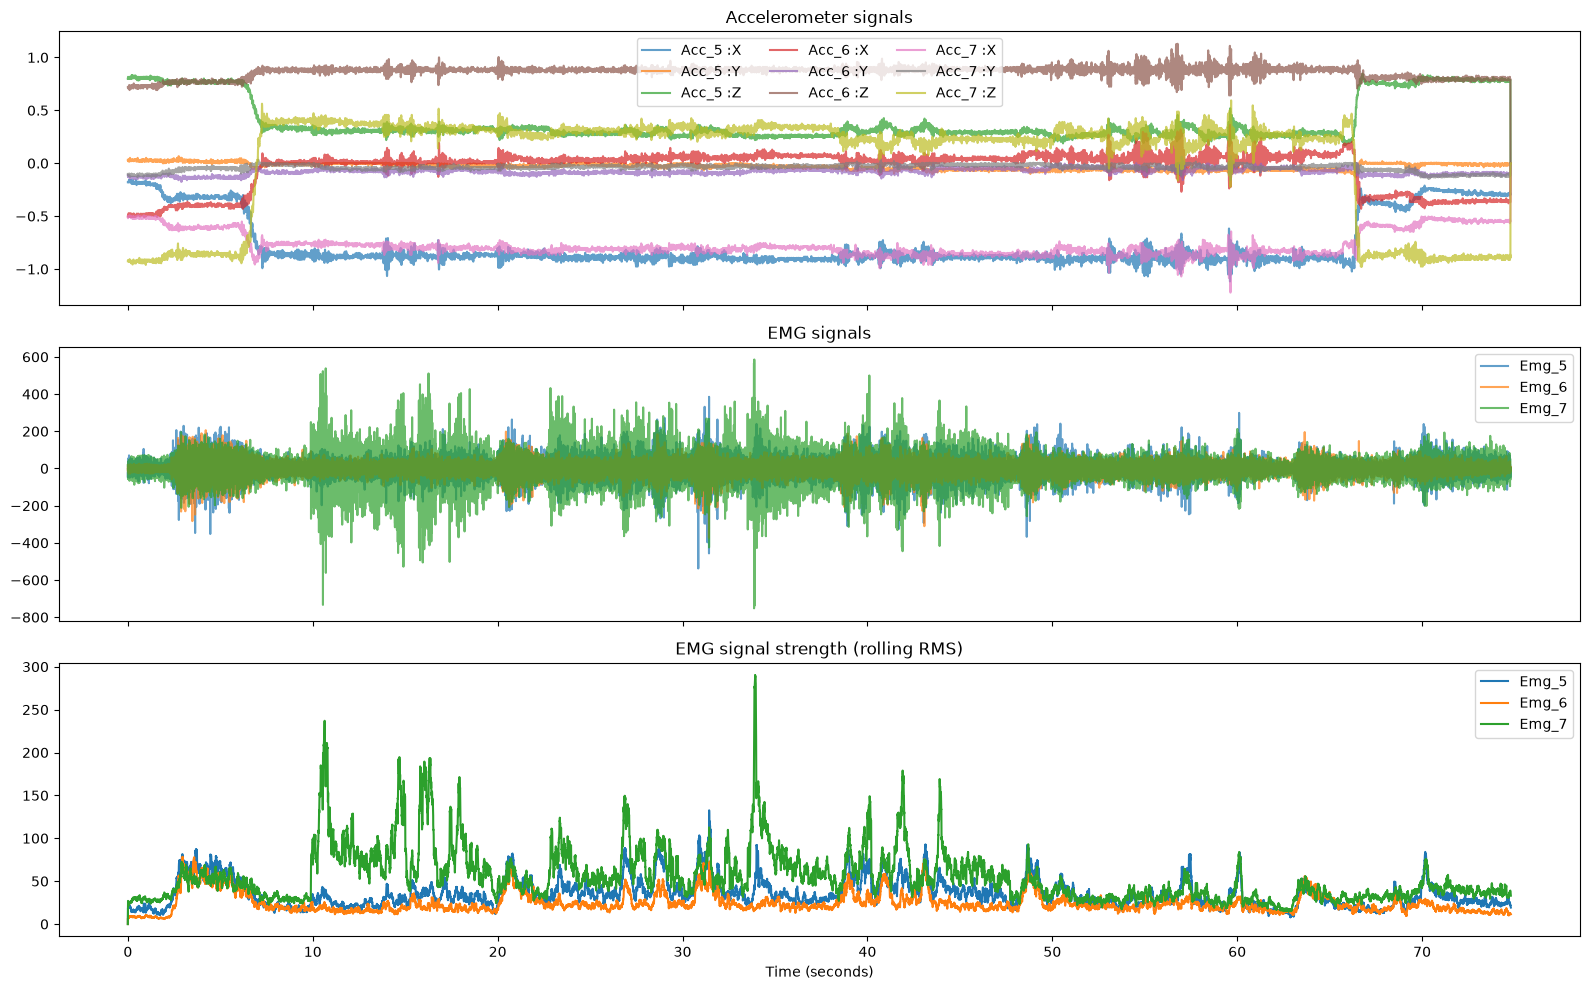

In [285]:
fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)



# Accelerometer
for col in df_xyz.columns:
    axes[0].plot(time, df_xyz[col], label=col, alpha=0.7)

axes[0].set_title("Accelerometer signals")
axes[0].legend(ncol=3)

# EMG
for col in df_emg_acc.columns:
    axes[1].plot(time, df_emg_acc[col], label=col, alpha=0.7)

axes[1].set_title("EMG signals")
axes[1].legend()

# Example: EMG signal strength
for col in df_emg_acc.columns:
    envelope = (
        df_emg_acc[col]
        .rolling(200, min_periods=1)
        .apply(lambda x: np.sqrt(np.mean((x - x.mean())**2))
               , raw=True)
    )
    axes[2].plot(time, envelope, label=col)

axes[2].set_title("EMG signal strength (rolling RMS)")
axes[2].set_xlabel("Time (seconds)")
axes[2].legend()

plt.tight_layout()
plt.show()

Die zugehörigen Bewegungen nach plan

1. Hand zu Faust langsam ballen und 2-3 Sekunden halten (Daumen wird nicht umschlossen von anderen Fingern)
2. Hand Drehung um 45 Grad nach oben gegen den Uhrzeigersinn
3. Zeigefinger austrecken
4. Handform beibehalten und drei Wischbewegungen von rechts nach links (Mit Reset)
5. Hand zu Faust zurück ballen
6. Daumen hoch
7. Daumen drei mal auf Zeigefinger drücken
8. Zeigefinger mit gestreckten Daumen ausstrecken
9. "Pinch Bewegung" von Daumen und Zeige Finger drei mal
10. Hand zu Faust zurück ballen
11. Mittelfinger und Zeigefinger austrecken
12. Handform beibehalten und drei Wischbewegungen von rechts nach links mit beiden Fingern (Mit Reset)
13. Hand zu Faust zurück ballen
14. and Drehung um 45 Grad zur Seite gegen im Uhrzeigersinn
15. Faust zur falchen Hand zurück formen

In [286]:
movement_intervals = [

    (0, 3, 0),
    (3, 9, 1),
    (9, 12, 2),
    (12, 14, 3),
    (14, 18, 4),
    (18, 22, 5),
    (22, 26, 6),
    (26, 30, 7),
    (30, 35, 8),
    (35, 42, 9),
    (42, 44, 10),
    (44, 50, 11), 
    (50, 60, 12), 
    (60, 69, 13), 
    (69, 72, 14), 
    (72, 74, 15)
]


In [287]:

def extract_features(data, time, intervals,
                     window_size=200, step_size=100):

    features = []
    labels = []
    window_times = []

    for start in range(0, len(data) - window_size + 1, step_size):

        end = start + window_size

        window = data.iloc[start:end]
        window_time = time.iloc[start:end]

        # Use the middle timestamp to identify the movement
        middle_time = window_time.iloc[len(window_time) // 2]

        # Only keep windows completely inside one movement
        movement = next(
            (m for t_start, t_end, m in intervals
             if window_time.iloc[0] >= t_start
             and window_time.iloc[-1] < t_end),
            None
        )

        if movement is None:
            continue

        row = {}

        for col in data.columns:
            signal = window[col].to_numpy()

            row[col + "_mean"] = np.mean(signal)
            row[col + "_std"] = np.std(signal)
            row[col + "_min"] = np.min(signal)
            row[col + "_max"] = np.max(signal)

            # RMS after removing the signal's mean
            centered = signal - np.mean(signal)
            row[col + "_rms"] = np.sqrt(np.mean(centered ** 2))

        features.append(row)
        labels.append(movement)
        window_times.append(middle_time)

    return (
        pd.DataFrame(features),
        np.array(labels),
        np.array(window_times)
    )

- 45 features for accelerometer data.
- 15 features for EMG data.
- 60 features for combined data.

In [288]:
X_xyz, y_xyz, time_xyz = extract_features(
    df_xyz, time, movement_intervals
)

X_emg, y_emg, time_emg = extract_features(
    df_emg_acc, time, movement_intervals
)

X_combined, y_combined, time_combined = extract_features(
    df_combined, time, movement_intervals
)

## Daten Normalisierung

In [289]:

scaler = StandardScaler()

X_xyz_scaled = scaler.fit_transform(X_xyz)
X_emg_scaled = scaler.fit_transform(X_emg)
X_combined_scaled = scaler.fit_transform(X_combined)

In [298]:
kmeans = KMeans(
    n_clusters=16,
    random_state=42,
    n_init=10
)

clusters_xyz = kmeans.fit_predict(X_xyz_scaled)
clusters_emg = kmeans.fit_predict(X_emg_scaled)
clusters_combined = kmeans.fit_predict(X_combined_scaled)

In [318]:

dbscan = DBSCAN(
    eps=2.25,
    min_samples=10
)

dbscan_xyz = dbscan.fit_predict(X_xyz_scaled)
dbscan_emg = dbscan.fit_predict(X_emg_scaled)
dbscan_combined = dbscan.fit_predict(X_combined_scaled)

## XYZ scaled

In [319]:


X_pca_xyz = PCA(n_components=2).fit_transform(X_xyz_scaled)
X_pca_emg = PCA(n_components=2).fit_transform(X_emg_scaled)
X_pca_combined = PCA(n_components=2).fit_transform(X_combined_scaled)

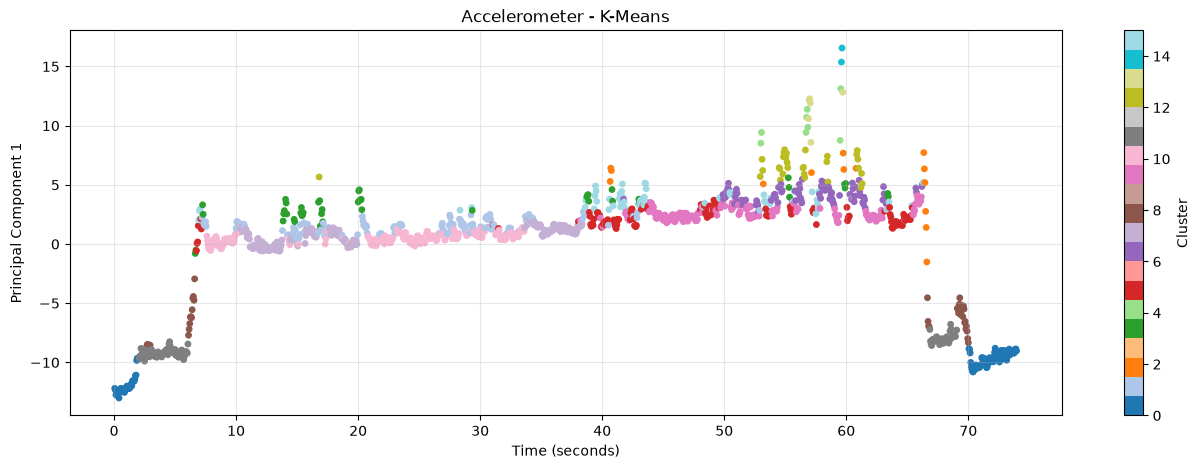

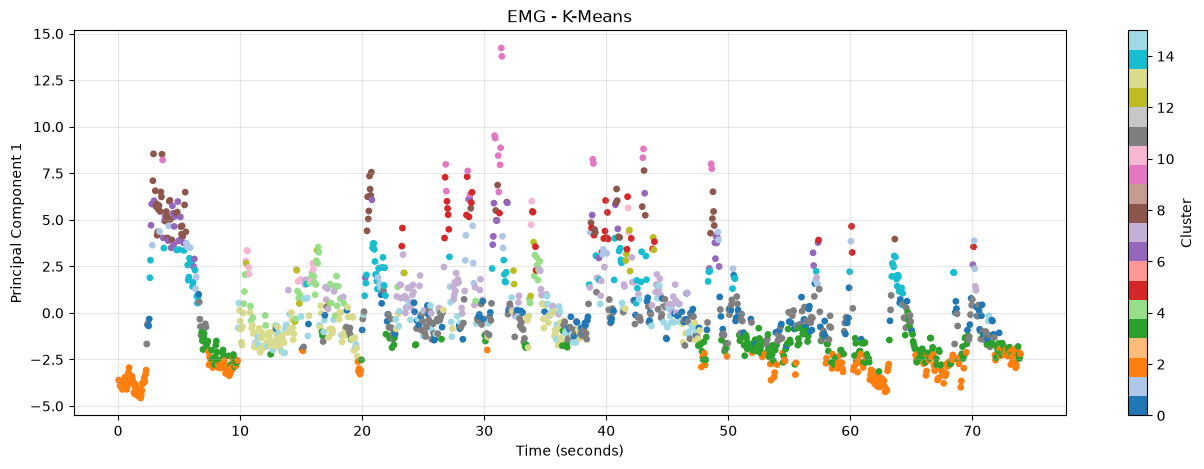

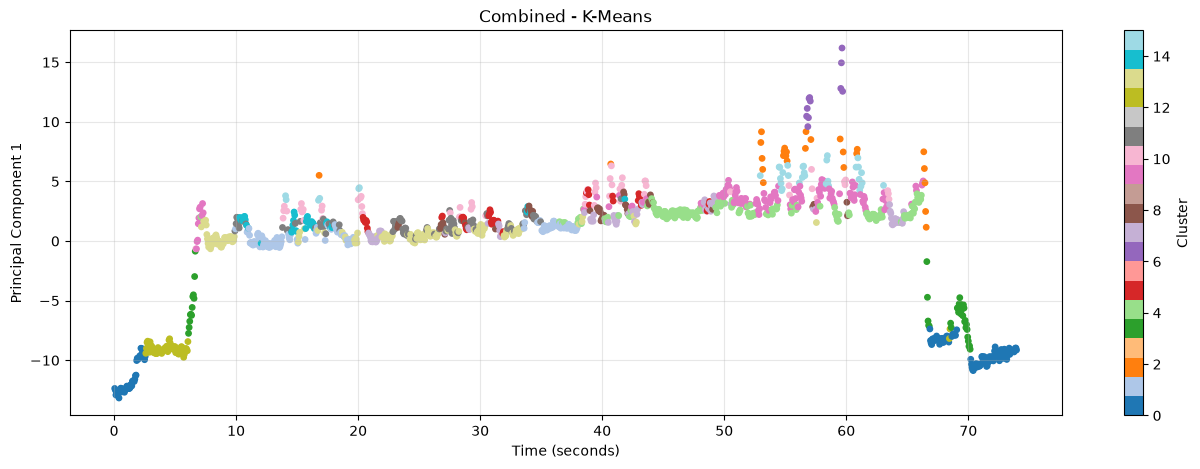

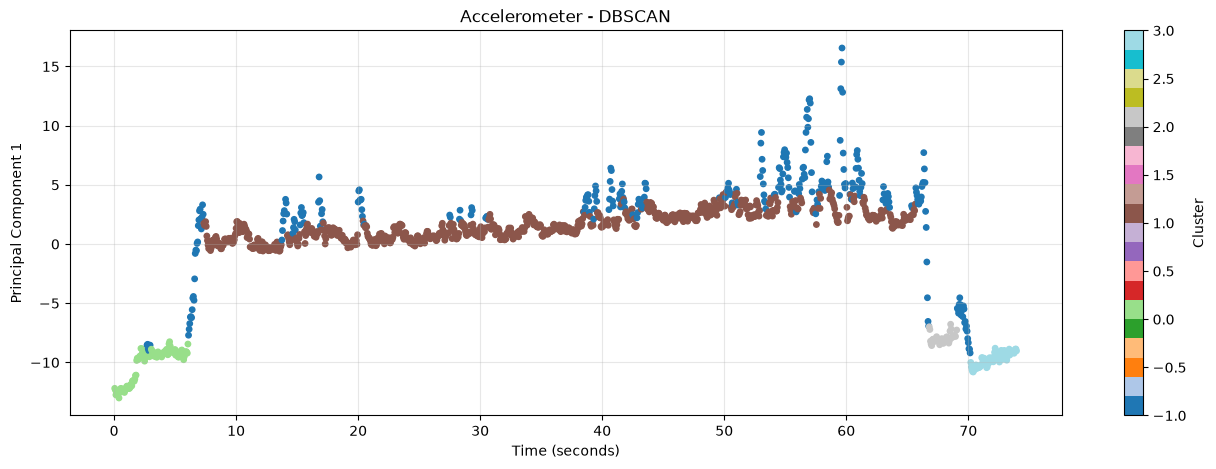

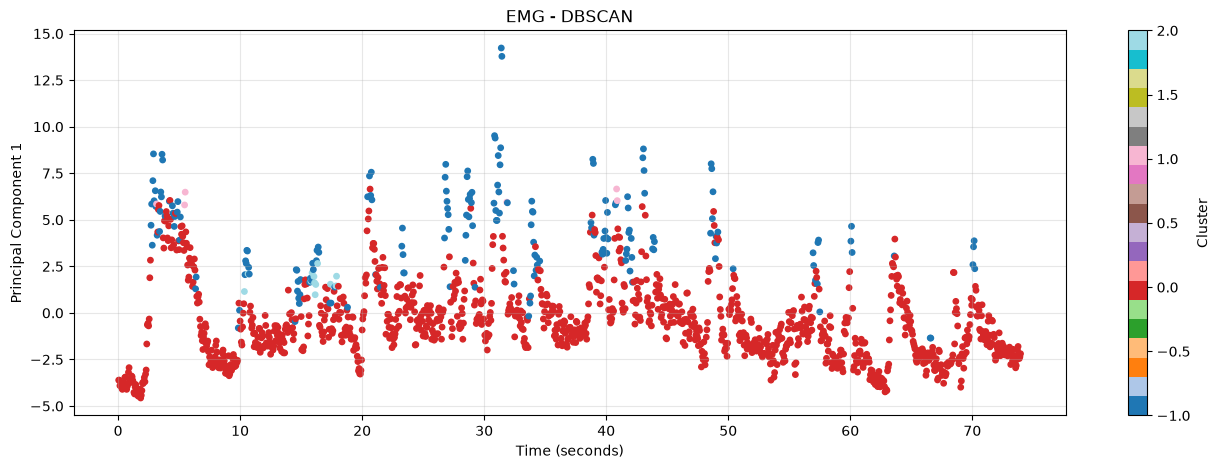

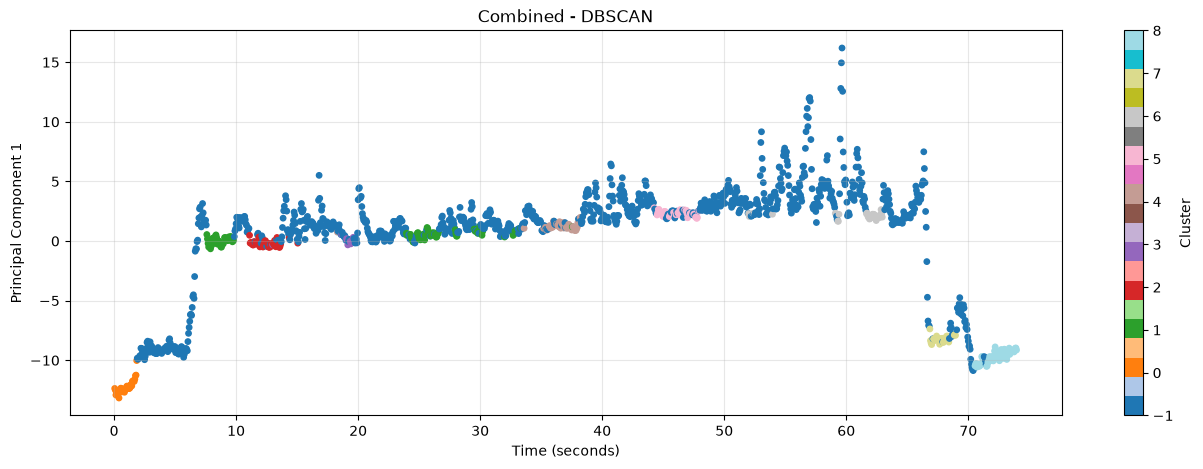

In [320]:


def plot_clusters_over_time(times, X_pca, labels, title):

    plt.figure(figsize=(16, 5))

    plt.scatter(
        times,
        X_pca[:, 0],
        c=labels,
        cmap="tab20",
        s=15
    )

    plt.xlabel("Time (seconds)")
    plt.ylabel("Principal Component 1")
    plt.title(title)
    plt.colorbar(label="Cluster")
    plt.grid(alpha=0.3)
    plt.show()



plot_clusters_over_time(
    time_xyz,
    X_pca_xyz,
    clusters_xyz,
    "Accelerometer - K-Means"
)

plot_clusters_over_time(
    time_emg,
    X_pca_emg,
    clusters_emg,
    "EMG - K-Means"
)

plot_clusters_over_time(
    time_combined,
    X_pca_combined,
    clusters_combined,
    "Combined - K-Means"
)

plot_clusters_over_time(
    time_xyz,
    X_pca_xyz,
    dbscan_xyz,
    "Accelerometer - DBSCAN"
)

plot_clusters_over_time(
    time_emg,
    X_pca_emg,
    dbscan_emg,
    "EMG - DBSCAN"
)

plot_clusters_over_time(
    time_combined,
    X_pca_combined,
    dbscan_combined,
    "Combined - DBSCAN"
)


### Vergleich mit selbst gesetzten Intervallen

In [321]:
def get_movement_labels(times, movement_intervals):

    true_labels = []

    for t in times:

        movement = -1

        for start, end, movement_id in movement_intervals:
            if start <= t < end:
                movement = movement_id
                break

        true_labels.append(movement)

    return np.array(true_labels)

In [322]:



datasets = {
    "Accelerometer": X_xyz_scaled,
    "EMG": X_emg_scaled,
    "Combined": X_combined_scaled
}
clustering_results = {
    "Accelerometer": {"K-Means": clusters_xyz, "DBSCAN": dbscan_xyz}
    ,"EMG": {"K-Means": clusters_emg, "DBSCAN": dbscan_emg}
    ,"Combined": {"K-Means": clusters_combined, "DBSCAN": dbscan_combined}}

time_datasets = {
    "Accelerometer": time_xyz,
    "EMG": time_emg,
    "Combined": time_combined
}

results = []

for name, algorithms in clustering_results.items():

    X = datasets[name]
    times = time_datasets[name]

    true_labels = get_movement_labels(
        times, movement_intervals
    )

    # Remove windows without a movement label
    valid = true_labels != -1

    for algorithm, predicted in algorithms.items():

        y_true = true_labels[valid]
        y_pred = predicted[valid]
        X_valid = X[valid]

        ari = adjusted_rand_score(y_true, y_pred)

        nmi = normalized_mutual_info_score(y_true, y_pred)

        # DBSCAN noise points (-1) excluded from silhouette
        if algorithm == "DBSCAN":
            mask = y_pred != -1
        else:
            mask = np.ones(len(y_pred), dtype=bool)

        unique_clusters = np.unique(y_pred[mask])

        if len(unique_clusters) >= 2 and mask.sum() > len(unique_clusters):
            silhouette = silhouette_score(
                X_valid[mask],
                y_pred[mask]
            )
        else:
            silhouette = np.nan

        results.append({
            "Dataset": name,
            "Algorithm": algorithm,
            "Clusters": len(unique_clusters),
            "Noise points": np.sum(y_pred == -1),
            "ARI": ari,
            "NMI": nmi,
            "Silhouette": silhouette
        })

results_df = pd.DataFrame(results)

print(results_df.round(3).to_string(index=False))

      Dataset Algorithm  Clusters  Noise points   ARI   NMI  Silhouette
Accelerometer   K-Means        16             0 0.214 0.469       0.196
Accelerometer    DBSCAN         4           293 0.052 0.299       0.574
          EMG   K-Means        16             0 0.106 0.250       0.130
          EMG    DBSCAN         3           186 0.010 0.047       0.376
     Combined   K-Means        16             0 0.221 0.454       0.174
     Combined    DBSCAN         9          1037 0.046 0.346       0.277


### Visualisierung der Heatmap von gelabelten Clustern mit berechneten

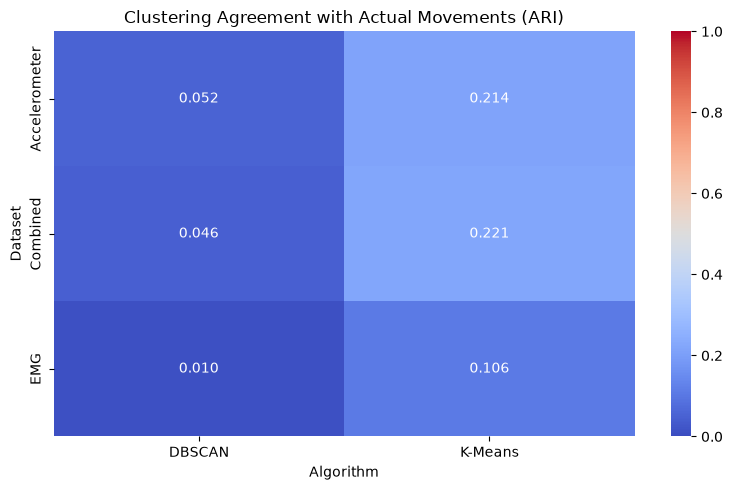

In [323]:
comparison = results_df.pivot(
    index="Dataset",
    columns="Algorithm",
    values="ARI"
)

plt.figure(figsize=(8, 5))

sns.heatmap(
    comparison,
    annot=True,
    cmap="coolwarm",
    vmin=0,
    vmax=1,
    fmt=".3f"
)

plt.title("Clustering Agreement with Actual Movements (ARI)")
plt.tight_layout()
plt.show()

### Cluster Vergleich

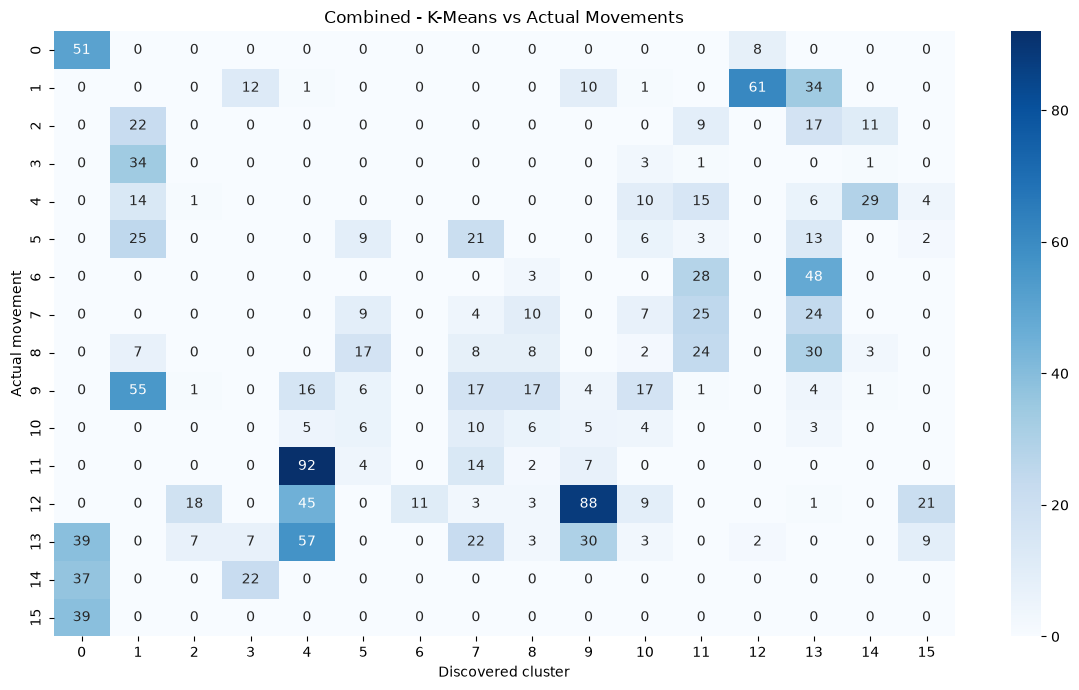

In [324]:
from sklearn.metrics.cluster import contingency_matrix


def plot_movement_comparison(true_labels, predicted_labels, title):

    matrix = contingency_matrix(
        true_labels,
        predicted_labels
    )

    plt.figure(figsize=(12, 7))

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.xlabel("Discovered cluster")
    plt.ylabel("Actual movement")
    plt.title(title)
    plt.tight_layout()
    plt.show()

plot_movement_comparison(
    y_true,
    clusters_combined,
    "Combined - K-Means vs Actual Movements"
)

### Erkenntnis

Die eigentlichen Bewegungsabschnitte zu labeln ist zwar nett, bringt bei den Daten nur semi viel, aber die besten Daten für Clustering scheinen die kombinierten aus EMG und Acc zu sein, wobei Acc kanpp dahinter ist und EMG stark abfällt

Daher testen von anderen Paramtern für K-Means und Clustering

K-Means Testing

In [325]:
for k in range(2, 21):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_combined_scaled)

    score = silhouette_score(
        X_combined_scaled,
        labels
    )

    print(f"K={k}: Silhouette={score:.3f}")

K=2: Silhouette=0.449
K=3: Silhouette=0.460
K=4: Silhouette=0.282
K=5: Silhouette=0.267
K=6: Silhouette=0.260
K=7: Silhouette=0.222
K=8: Silhouette=0.222
K=9: Silhouette=0.213
K=10: Silhouette=0.207
K=11: Silhouette=0.181
K=12: Silhouette=0.176
K=13: Silhouette=0.187
K=14: Silhouette=0.155
K=15: Silhouette=0.178
K=16: Silhouette=0.174
K=17: Silhouette=0.158
K=18: Silhouette=0.157
K=19: Silhouette=0.166
K=20: Silhouette=0.165


DBSCAN Testing

In [ ]:


for eps in [0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.25, 2.5, 2.75, 3.0]:
    model = DBSCAN(
        eps=eps,
        min_samples=10
    )

    labels = model.fit_predict(X_combined_scaled)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise = sum(labels == -1)

    print(
        f"eps={eps}: "
        f"Clusters={n_clusters}, "
        f"Noise={noise}"
    )

eps=0.5: Clusters=0, Noise=1464
eps=0.75: Clusters=0, Noise=1464
eps=1.0: Clusters=0, Noise=1464
eps=1.25: Clusters=0, Noise=1464
eps=1.5: Clusters=0, Noise=1464
eps=2.0: Clusters=8, Noise=1196
eps=2.25: Clusters=9, Noise=1037
eps=2.5: Clusters=7, Noise=859
eps=2.75: Clusters=4, Noise=745
eps=3.0: Clusters=5, Noise=607


### Erkenntnis:

8 scheinen die Beste Zuordnung bei den Daten zu sein

In [338]:


# Reduce data to 2 dimensions for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_combined_scaled)

# K-Means with 8 clusters
kmeans_8 = KMeans(
    n_clusters=8,
    random_state=42,
    n_init=10
)
# K-Means with 9 clusters
kmeans_9 = KMeans(
    n_clusters=9,
    random_state=42,
    n_init=10
)
clusters_8 = kmeans_8.fit_predict(X_combined_scaled)
clusters_9 = kmeans_9.fit_predict(X_combined_scaled)


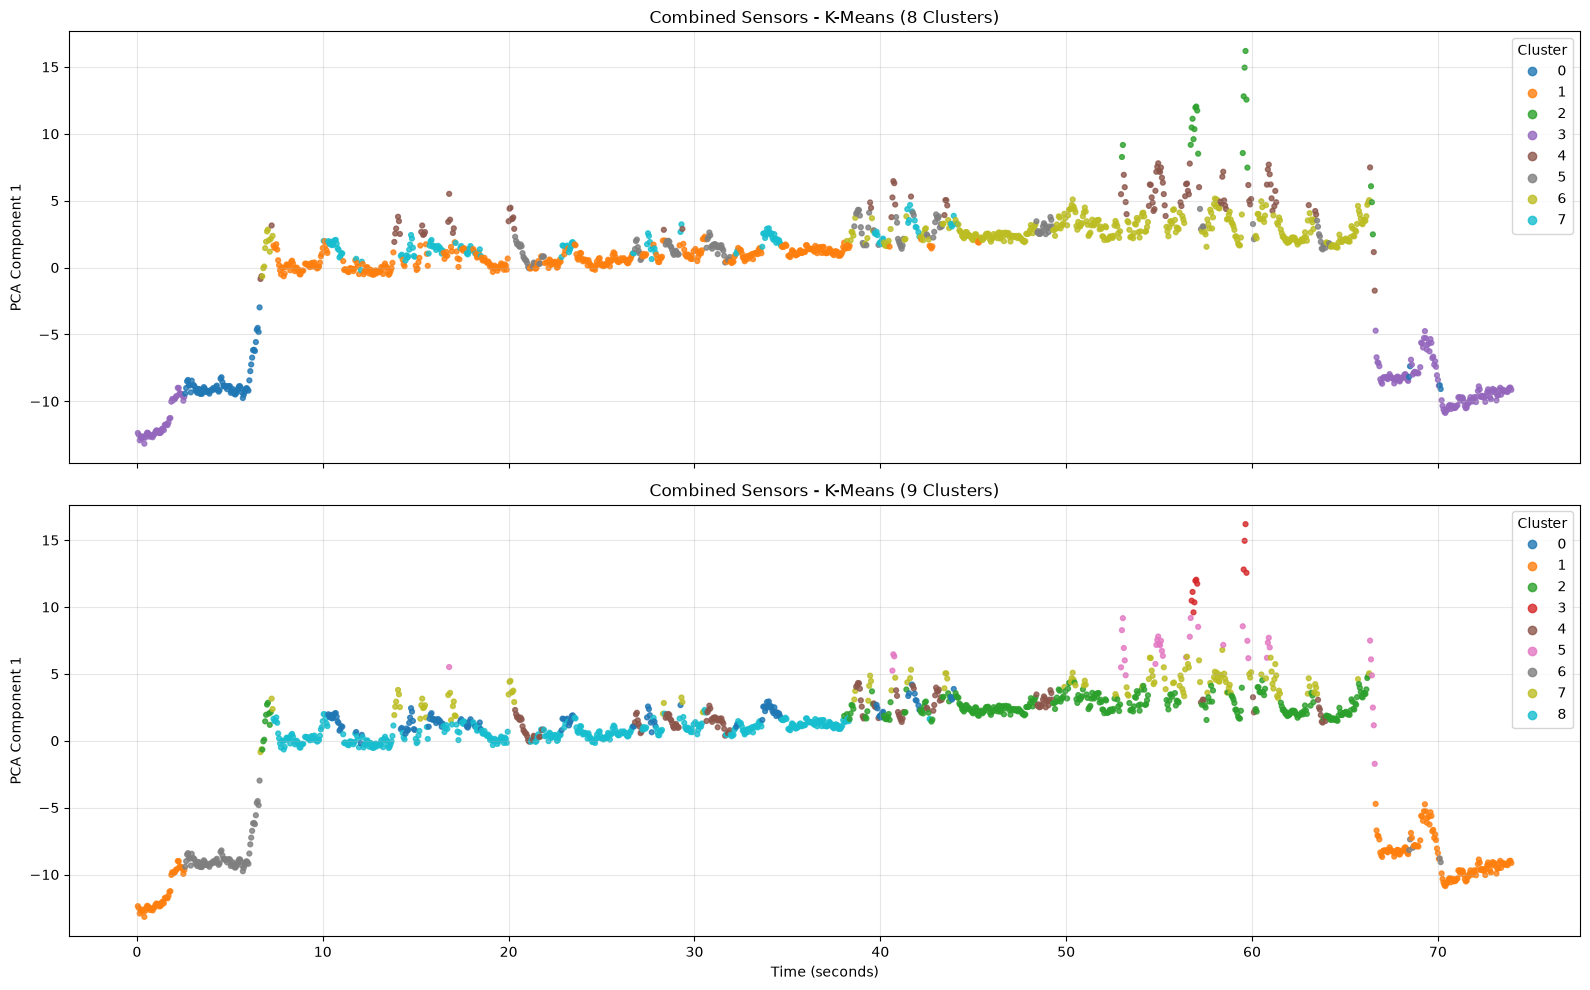

In [339]:
fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

cluster_results = {
    "8 Clusters": clusters_8,
    "9 Clusters": clusters_9
}

for ax, (name, labels) in zip(axes, cluster_results.items()):

    scatter = ax.scatter(
        time_combined,
        X_pca[:, 0],
        c=labels,
        cmap="tab10",
        s=12,
        alpha=0.8
    )

    ax.set_title(f"Combined Sensors - K-Means ({name})")
    ax.set_ylabel("PCA Component 1")
    ax.grid(alpha=0.3)
    ax.legend(*scatter.legend_elements(), title="Cluster")

axes[-1].set_xlabel("Time (seconds)")

plt.tight_layout()
plt.show()

## Samuel Teil Bericht

### CSV Konvertierung

Ein Python Skript wurde erstellt um c3d Dateien in ein CSV Format umzuwandeln.
Dadurch wurden die erste Testdatenreihe konviertiert für die weitere Verarbeitung.

### Inhalt der CSV

In der datei sidn folgende Daten vorhanden:

```csv
Time,Emg_1,Acc_1 :X,Acc_1 :Y,Acc_1 :Z,Emg_2,Acc_2 :X,Acc_2 :Y,Acc_2 :Z,Acc_3 :X,Acc_3 :Y,Acc_3 :Z,Emg_4,Acc_4 :X,Acc_4 :Y,Acc_4 :Z,Emg_5,Acc_5 :X,Acc_5 :Y,Acc_5 :Z,Emg_6,Acc_6 :X,Acc_6 :Y,Acc_6 :Z,Emg_7,Acc_7 :X,Acc_7 :Y,Acc_7 :Z,Acc_8 :X,Acc_8 :Y,Acc_8 :Z,Acc_9 :X,Acc_9 :Y,Acc_9 :Z,Acc_10 :X,Acc_10 :Y,Acc_10 :Z,Acc_11 :X,Acc_11 :Y,Acc_11 :Z,Acc_12 :X,Acc_12 :Y,Acc_12 :Z,Acc_13 :X,Acc_13 :Y,Acc_13 :Z,Acc_14 :X,Acc_14 :Y,Acc_14 :Z,Acc_15 :X,Acc_15 :Y,Acc_15 :Z,Acc_16 :X,Acc_16 :Y,Acc_16 :Z
```
Time ist ein abiträr hinzugefügtes Feature, das den zeitlichen Rahmen für jede Testwertzeile im halben millisekunden Takt klassifiziert.
Beim direkten untersuchen der Daten konnte festgestellt werden, dass
sehr viele spalten gar keine Werte beritstellen.
Grund: Es wurden nicht alle verfügbaren Sensoren des EMG Gerätes für diese Testreihe angwandt, aber natürlich als Werte (überall 0) mit aufgenommen.
Zu diesen zählen:

Emg_1, Emg_2, Emg_4, Acc_1 :X, Acc_1 :Y, Acc_1 :Z, Acc_2 :X, Acc_2 :Y, Acc_2 :Z, Acc_3 :X, Acc_3 :Y, Acc_3 :Z, Acc_4 :X, Acc_4 :Y, Acc_4 :Z, Acc_8 :X, Acc_8 :Y, Acc_8 :Z, Acc_9 :X, Acc_9 :Y, Acc_9 :Z, Acc_10 :X, Acc_10 :Y, Acc_10 :Z, Acc_11 :X, Acc_11 :Y, Acc_11 :Z, Acc_12 :X, Acc_12 :Y, Acc_12 :Z, Acc_13 :X, Acc_13 :Y, Acc_13 :Z, Acc_14 :X, Acc_14 :Y, Acc_14 :Z, Acc_15 :X, Acc_15 :Y, Acc_15 :Z, Acc_16 :X, Acc_16 :Y, Acc_16 :Z.

Die Daten mit tatsächlichen Werten(Die drei verwendeten Sensoren):
Acc_5 :X,	Acc_5 :Y,	Acc_5 :Z,	Acc_6 :X,	Acc_6 :Y,	Acc_6 :Z,	Acc_7 ,:X,	Acc_7 :Y,	Acc_7 :Z,	Emg_5,	Emg_6,	Emg_7,

Hierbei wurde ermittelt, dass EMG Spalten die eigentlichen EMG Daten sind und Acc_<Zahl> :XYZ die gemessene Beschleunigung des einzelnen Sensor in die jweilige Richtung ist

### Datenaufbereitung 

Um die Daten besser auswerten zu können, wurde ein jupyter Notebook verwendet.
In diesem wurden alle csv Daten erstaml importiert und alle und leeren spalten gelöscht. danach wurde Time als separte Spalte extrahiert sowie drei weitere Datensätze erstellt:
1. Nur die Beschleunigungsdaten
2. Nur die EMG Daten
3. Beide Datensätze kombiniert

Hiernach wurde  alle drei datensätze gegenbüber dem Zeitverlauf visualisiert. 
Aus den hervorgehenden Graphen wurden dann in die 15 Phasen, die für den ersten Testlauf als Richtlinie dienten, eingeteilt.

### Clustering

Um erstmal zu gucken, ob diese 15 Phasen tatsächlich, in den Daten geclustert werden können wurden die K-Means und DBSAN Algorithmen angewandt.
Das Ergebnis zeigte, dass es wenig Sinn machte, die Daten in bestimmte intervalle zu teilen. Die Intervall basierte aufteilung besaß nämlich eine sehr geringe Korrelation mit dem durchgeführten Clustering.

Dennoch gab es große Differenzen zwischen den datensätzen.
Während der 3. datensatz das beste Ergebnis lieferte und der 1. knapp dahinter waren, gab der alleinige EMg Datensatz ein sehr schlechtes Ergebnis bei beiden Cluster Algorithmen.
Erkenntnis: Alle Daten sind (vorerst) am besten für die weietere Analyse & später das Training geeignet.

Als letzter Schritt wurde gemessen wie viele Cluster in diesen Daten die sauberste und beste Aufteilung liefern. Dabei wurde mittels zwei verschieener Verfahren für DBSACN und auch K-Maens festgestellt, dass zwischen 7-9 Cluster die beste Datenaufteilung liefern

### Fazit

Auf Basis der durchgeführten Datenanalyse können vertiefende Analyen durchgeführt werden und weitere Testreihen untersucht werden, um die ersten Modelle zu erstellen.


